In [13]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Brain Tumor.zip'
extract_path = '/content/BrainTumor'

# Extract only if folder doesn't exist
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("✅ Dataset extracted.")
else:
    print("Dataset already extracted.")

Dataset already extracted.


In [15]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import os


In [16]:
IMG_SIZE = (299, 299)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 5712 images belonging to 4 classes.
Found 1311 images belonging to 4 classes.


In [17]:
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))

# Freeze the base layers
for layer in base_model.layers:
    layer.trainable = False

# Add custom layers on top
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(train_gen.num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)


In [18]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [19]:
history = model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=20,
    verbose=1
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 177s 870ms/step - accuracy: 0.4662 - loss: 1.2573 - val_accuracy: 0.7536 - val_loss: 0.6379
Epoch 2/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 130s 724ms/step - accuracy: 0.7255 - loss: 0.7007 - val_accuracy: 0.7811 - val_loss: 0.5789
Epoch 3/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 129s 721ms/step - accuracy: 0.7638 - loss: 0.6118 - val_accuracy: 0.7963 - val_loss: 0.5302
Epoch 4/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 128s 717ms/step - accuracy: 0.7874 - loss: 0.5526 - val_accuracy: 0.7956 - val_loss: 0.5389
Epoch 5/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 129s 717ms/step - accuracy: 0.7948 - loss: 0.5396 - val_accuracy: 0.8169 - val_loss: 0.4895
Epoch 6/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 130s 723ms/step - accuracy: 0.8153 - loss: 0.4824 - val_accuracy: 0.8177 - val_loss: 0.4930
Epoch 7/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 129s 721ms/step - accuracy: 0.8303 - loss: 0.4501 - val_accuracy: 0.8215 - val_loss: 0.4671
Epoch 8/20
179/179 ━━━━━━━━━━━━━━━━━━━━ 128s 716ms/step - accuracy: 0.8281 -

In [20]:
for layer in base_model.layers[-100:]:
    layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=10,
    verbose=1
)


Epoch 1/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 189s 877ms/step - accuracy: 0.6978 - loss: 0.7875 - val_accuracy: 0.8589 - val_loss: 0.3408
Epoch 2/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 134s 746ms/step - accuracy: 0.8749 - loss: 0.3404 - val_accuracy: 0.8886 - val_loss: 0.2878
Epoch 3/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 132s 739ms/step - accuracy: 0.8957 - loss: 0.2799 - val_accuracy: 0.9016 - val_loss: 0.2347
Epoch 4/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 134s 748ms/step - accuracy: 0.9103 - loss: 0.2349 - val_accuracy: 0.9298 - val_loss: 0.1955
Epoch 5/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 133s 741ms/step - accuracy: 0.9266 - loss: 0.1965 - val_accuracy: 0.9359 - val_loss: 0.1646
Epoch 6/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 133s 741ms/step - accuracy: 0.9325 - loss: 0.1837 - val_accuracy: 0.9428 - val_loss: 0.1402
Epoch 7/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 132s 739ms/step - accuracy: 0.9418 - loss: 0.1560 - val_accuracy: 0.9466 - val_loss: 0.1264
Epoch 8/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 135s 751ms/step - accuracy: 0.9508 -

In [21]:
loss, acc = model.evaluate(test_gen)
print(f"✅ Test Accuracy: {acc*100:.2f}%")


41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 119ms/step - accuracy: 0.9538 - loss: 0.1094
✅ Test Accuracy: 96.57%


In [22]:
model.save('/content/drive/MyDrive/inceptionv3_brain_tumor_model.h5')
print("Model saved to Drive ✅")


Model saved to Drive ✅


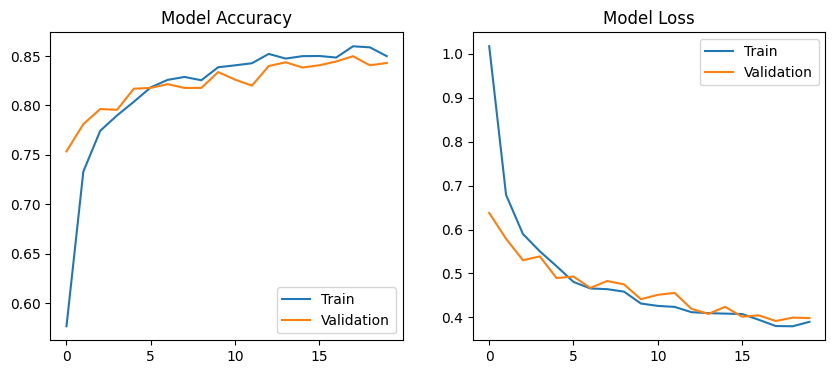

In [23]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.legend()
plt.show()


41/41 ━━━━━━━━━━━━━━━━━━━━ 17s 277ms/step


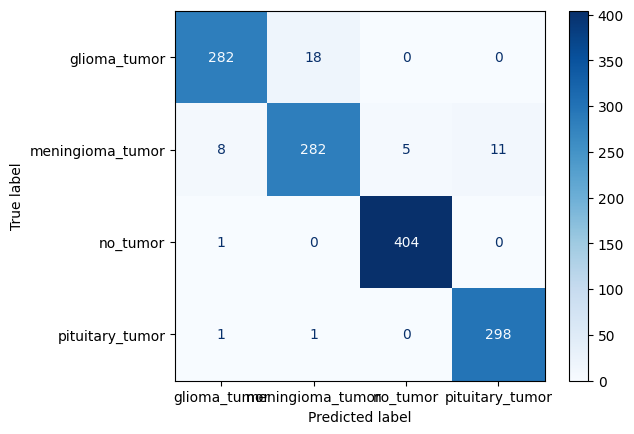

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# Get true labels
true_labels = test_gen.classes

# Get predicted labels
predictions = model.predict(test_gen)
predicted_labels = np.argmax(predictions, axis=1)

# Generate confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [24]:
from tensorflow.keras.models import load_model

model_path = '/content/drive/MyDrive/inceptionv3_brain_tumor_model.h5'
model = load_model(model_path)
print("✅ Model loaded successfully!")




✅ Model loaded successfully!


Saving image(56).jpg to image(56).jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


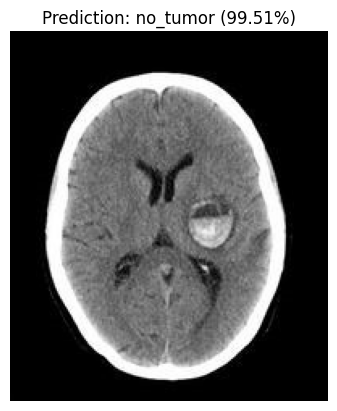

In [31]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np

uploaded = files.upload()
import matplotlib.pyplot as plt
import tensorflow as tf

# Class names must match your dataset folder structure
class_names = ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']

for fname in uploaded.keys():
    img_path = fname

    # Load and preprocess the image
    img = image.load_img(img_path, target_size=(299, 299))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.inception_v3.preprocess_input(img_array)

    # Predict
    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = np.max(predictions[0]) * 100

    # Show result
    plt.imshow(image.load_img(img_path))
    plt.axis('off')
    plt.title(f"Prediction: {predicted_class} ({confidence:.2f}%)")
    plt.show()